In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

tp = pd.read_csv('touchpoints.csv')
up = pd.read_csv('user_profiles.csv')
cs = pd.read_csv('campaign_spend.csv')

print("Touchpoints:", tp.shape)
print("User Profiles:", up.shape)
print("Campaign Spend:", cs.shape)

print("\nTouchpoints columns:", tp.columns.tolist())
print("User Profiles columns:", up.columns.tolist())
print("Campaign Spend columns:", cs.columns.tolist())

Touchpoints: (47796, 5)
User Profiles: (88163, 4)
Campaign Spend: (50, 6)

Touchpoints columns: ['User_ID', 'Timestamp', 'Campaign_ID', 'Channel', 'Event_Type']
User Profiles columns: ['User_ID', 'Segment', 'Trend_Affinity', 'Geography']
Campaign Spend columns: ['Campaign_ID', 'Brand_ID', 'Channel', 'Pricing_Model', 'Cost_Rate_INR', 'Total_Budget_Allocated']


In [ ]:
print("=== TOUCHPOINTS ===")
print(tp.head(10))
print("\nEvent types:", tp['Event_Type'].value_counts())
print("\nChannels:", tp['Channel'].value_counts())

print("\n=== USER PROFILES ===")
print(up.head())
print("\nSegments:", up['Segment'].value_counts())

print("\n=== CAMPAIGN SPEND ===")
print(cs.head(10))
print("\nBrands:", cs['Brand_ID'].value_counts())
print("\nPricing Models:", cs['Pricing_Model'].value_counts())

=== TOUCHPOINTS ===
       User_ID       Timestamp      Campaign_ID          Channel  Event_Type
0  U_B01_00000  1/1/2026 19:27  CMP_B01_INF_899  Influencer Blog  Impression
1  U_B01_00001  1/1/2026 20:37  CMP_B01_GOO_434    Google Search  Impression
2  U_B01_00001  1/1/2026 20:38  CMP_B01_GOO_434    Google Search       Click
3  U_B01_00001  1/4/2026 15:37  CMP_B01_MAR_127      Marketplace  Impression
4  U_B01_00001   1/6/2026 8:37  CMP_B01_INS_285        Instagram  Impression
5  U_B01_00001  1/7/2026 15:37  CMP_B01_INF_899  Influencer Blog  Impression
6  U_B01_00002  1/1/2026 11:52  CMP_B01_MAR_127      Marketplace  Impression
7  U_B01_00002   1/4/2026 7:52  CMP_B01_GOO_434    Google Search  Impression
8  U_B01_00002  1/5/2026 16:52  CMP_B01_YOU_211          YouTube  Impression
9  U_B01_00002   1/6/2026 6:52  CMP_B01_INF_899  Influencer Blog  Impression

Event types: Event_Type
Impression     36540
Click          10439
Purchase         557
Add-to-Cart      259
Name: count, dtype: int6

In [ ]:
# Convert timestamp
tp['Timestamp'] = pd.to_datetime(tp['Timestamp'])
tp = tp.sort_values(['User_ID', 'Timestamp'])

# Find time difference between events per user
tp['time_diff'] = tp.groupby('User_ID')['Timestamp'].diff().dt.total_seconds()

# Flag bots - clicking faster than 2 seconds
bot_users = tp[tp['time_diff'] < 2]['User_ID'].unique()
print(f"Bot users found: {len(bot_users)}")
print(f"Bot records: {tp[tp['User_ID'].isin(bot_users)].shape[0]}")

# Clean data
clean_tp = tp[~tp['User_ID'].isin(bot_users)]
print(f"\nClean touchpoints: {clean_tp.shape[0]}")
print(f"Removed: {tp.shape[0] - clean_tp.shape[0]} records")

Bot users found: 970
Bot records: 21992

Clean touchpoints: 25804
Removed: 21992 records


In [ ]:
# Merge clean touchpoints with campaign spend
merged = clean_tp.merge(cs, on='Campaign_ID', how='left')
merged = merged.merge(up, on='User_ID', how='left')

# Calculate actual cost per event
def calc_cost(row):
    if row['Pricing_Model'] == 'CPC':
        if row['Event_Type'] == 'Click':
            return row['Cost_Rate_INR']
        else:
            return 0
    else:  # CPM
        if row['Event_Type'] == 'Impression':
            return row['Cost_Rate_INR'] / 1000
        else:
            return 0

merged['Actual_Cost'] = merged.apply(calc_cost, axis=1)

print("Merged shape:", merged.shape)
print(merged.head())

Merged shape: (25804, 15)
       User_ID           Timestamp      Campaign_ID        Channel_x  \
0  U_B01_00000 2026-01-01 19:27:00  CMP_B01_INF_899  Influencer Blog   
1  U_B01_00001 2026-01-01 20:37:00  CMP_B01_GOO_434    Google Search   
2  U_B01_00001 2026-01-01 20:38:00  CMP_B01_GOO_434    Google Search   
3  U_B01_00001 2026-01-04 15:37:00  CMP_B01_MAR_127      Marketplace   
4  U_B01_00001 2026-01-06 08:37:00  CMP_B01_INS_285        Instagram   

   Event_Type  time_diff Brand_ID        Channel_y Pricing_Model  \
0  Impression        NaN      B01  Influencer Blog           CPM   
1  Impression        NaN      B01    Google Search           CPC   
2       Click       60.0      B01    Google Search           CPC   
3  Impression   241140.0      B01      Marketplace           CPC   
4  Impression   147600.0      B01        Instagram           CPM   

   Cost_Rate_INR  Total_Budget_Allocated             Segment  \
0         329.34             14499430.43  Fitness Enthusiast   
1   

In [ ]:
from collections import defaultdict

# Check column name first
print("Columns:", merged.columns.tolist())

# Use correct channel column
merged['Channel'] = merged['Channel_y']

# Build conversion paths per user per brand
purchases_df = merged[merged['Event_Type'] == 'Purchase']
print(f"Total purchase events: {len(purchases_df)}")
print(f"Converting users: {purchases_df['User_ID'].nunique()}")
print(f"Purchases by brand:\n{purchases_df['Brand_ID'].value_counts()}")

Columns: ['User_ID', 'Timestamp', 'Campaign_ID', 'Channel_x', 'Event_Type', 'time_diff', 'Brand_ID', 'Channel_y', 'Pricing_Model', 'Cost_Rate_INR', 'Total_Budget_Allocated', 'Segment', 'Trend_Affinity', 'Geography', 'Actual_Cost']
Total purchase events: 494
Converting users: 494
Purchases by brand:
Brand_ID
B01    494
Name: count, dtype: int64


In [ ]:
# Build journey for each converting user
all_journeys = []

for user in purchases_df['User_ID'].unique():
    user_events = merged[merged['User_ID'] == user].sort_values('Timestamp')
    channels = user_events['Channel'].tolist()
    journey = ['Start'] + channels + ['Purchase']
    all_journeys.append(journey)

# Count transitions
transitions = defaultdict(lambda: defaultdict(int))
for journey in all_journeys:
    for i in range(len(journey)-1):
        transitions[journey[i]][journey[i+1]] += 1

# Show transition counts
trans_df = pd.DataFrame(transitions).fillna(0).T
print("\nTransition Matrix:")
print(trans_df)


Transition Matrix:
                 Google Search  YouTube  Instagram  Marketplace  \
Start                     69.0     84.0      154.0         86.0   
Google Search            101.0     34.0      113.0         49.0   
YouTube                   46.0     94.0      116.0         50.0   
Marketplace               53.0     43.0      123.0         84.0   
Instagram                 53.0     85.0      235.0         74.0   
Influencer Blog           51.0     36.0      122.0         40.0   

                 Influencer Blog  Purchase  
Start                      101.0       0.0  
Google Search               36.0      40.0  
YouTube                     33.0      37.0  
Marketplace                 43.0      37.0  
Instagram                   80.0     336.0  
Influencer Blog            110.0      44.0  


In [ ]:
# The issue - User IDs contain brand info (U_B01_xxxxx)
# Extract brand from User_ID
merged['User_Brand'] = merged['User_ID'].str.extract(r'(B\d+)')
print("Users per brand:", merged['User_Brand'].value_counts())

# Check purchases per brand
purchases_df = merged[merged['Event_Type'] == 'Purchase']
print("\nPurchases per brand:", purchases_df['User_Brand'].value_counts())


Users per brand: User_Brand
B01    25804
Name: count, dtype: int64

Purchases per brand: User_Brand
B01    494
Name: count, dtype: int64


In [ ]:
def markov_attribution(brand_data):
    purchases = brand_data[brand_data['Event_Type'] == 'Purchase']['User_ID'].unique()

    if len(purchases) == 0:
        return None

    # Build journeys
    transitions = defaultdict(lambda: defaultdict(int))

    for user in purchases:
        user_events = brand_data[brand_data['User_ID'] == user].sort_values('Timestamp')
        channels = user_events['Channel'].tolist()
        journey = ['Start'] + channels + ['Purchase']
        for i in range(len(journey)-1):
            transitions[journey[i]][journey[i+1]] += 1

    # Calculate removal effect per channel
    channels = ['Instagram', 'Google Search', 'Influencer Blog', 'YouTube', 'Marketplace']
    total_purchases = len(purchases)

    removal_effect = {}
    for ch in channels:
        # Count purchases that touched this channel
        touched = 0
        for user in purchases:
            user_events = brand_data[brand_data['User_ID'] == user]
            if ch in user_events['Channel'].values:
                touched += 1
        removal_effect[ch] = touched / total_purchases

    return removal_effect

# Run for all brands
results = {}
for brand in merged['User_Brand'].unique():
    brand_data = merged[merged['User_Brand'] == brand]
    result = markov_attribution(brand_data)
    if result:
        results[brand] = result
        print(f"✅ {brand} done - {len(brand_data[brand_data['Event_Type']=='Purchase'])} purchases")

attribution_df = pd.DataFrame(results).T
print("\n=== CHANNEL ATTRIBUTION BY BRAND ===")
print(attribution_df.round(3))

✅ B01 done - 494 purchases

=== CHANNEL ATTRIBUTION BY BRAND ===
     Instagram  Google Search  Influencer Blog  YouTube  Marketplace
B01      0.775          0.474            0.526    0.492         0.49


In [ ]:
# Extract brand from User_ID in ORIGINAL touchpoints (before bot removal)
tp['User_Brand'] = tp['User_ID'].str.extract(r'(B\d+)')
print("All brands in raw data:", tp['User_Brand'].value_counts())

# Also check clean data
clean_tp['User_Brand'] = clean_tp['User_ID'].str.extract(r'(B\d+)')
print("\nBrands in clean data:", clean_tp['User_Brand'].value_counts())

All brands in raw data: User_Brand
B01    47796
Name: count, dtype: int64

Brands in clean data: User_Brand
B01    25804
Name: count, dtype: int64


/tmp/ipykernel_16372/3591739323.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clean_tp['User_Brand'] = clean_tp['User_ID'].str.extract(r'(B\d+)')


In [ ]:
# Remerge with brand extracted
merged2 = clean_tp.merge(cs, on='Campaign_ID', how='left')
merged2 = merged2.merge(up, on='User_ID', how='left')
merged2['Channel'] = merged2['Channel_y']
merged2['User_Brand'] = merged2['User_ID'].str.extract(r'(B\d+)')

print("Brands in merged:", merged2['User_Brand'].value_counts())
print("\nPurchases per brand:")
print(merged2[merged2['Event_Type']=='Purchase']['User_Brand'].value_counts())

Brands in merged: User_Brand
B01    25804
Name: count, dtype: int64

Purchases per brand:
User_Brand
B01    494
Name: count, dtype: int64


In [ ]:
# Fix - recalculate Actual_Cost in merged2
def calc_cost(row):
    if row['Pricing_Model'] == 'CPC':
        if row['Event_Type'] == 'Click':
            return row['Cost_Rate_INR']
        else:
            return 0
    else:  # CPM
        if row['Event_Type'] == 'Impression':
            return row['Cost_Rate_INR'] / 1000
        else:
            return 0

merged2['Actual_Cost'] = merged2.apply(calc_cost, axis=1)

# Total spend per channel for B01
spend_b01 = cs[cs['Brand_ID'] == 'B01']

channel_spend = merged2[merged2['User_Brand']=='B01'].groupby('Channel')['Actual_Cost'].sum()
channel_purchases = merged2[
    (merged2['User_Brand']=='B01') &
    (merged2['Event_Type']=='Purchase')
].groupby('Channel')['User_ID'].count()

print("=== B01 CHANNEL SPEND ===")
print(channel_spend.round(2))

print("\n=== B01 LAST TOUCH PURCHASES BY CHANNEL ===")
print(channel_purchases)

# True CPA calculation
attribution_scores = attribution_df.loc['B01']
total_purchases_b01 = 494

cpa_df = pd.DataFrame({
    'Total_Spend': channel_spend,
    'Attribution_Score': attribution_scores,
    'Attributed_Purchases': (attribution_scores * total_purchases_b01).round(0),
})

cpa_df['True_CPA'] = cpa_df['Total_Spend'] / cpa_df['Attributed_Purchases']
cpa_df['LastClick_CPA'] = cpa_df['Total_Spend'] / channel_purchases

print("\n=== TRUE CPA vs LAST CLICK CPA ===")
print(cpa_df.round(2))

=== B01 CHANNEL SPEND ===
Channel
Google Search      3979.70
Influencer Blog    1599.28
Instagram          1908.55
Marketplace        5443.30
YouTube             874.93
Name: Actual_Cost, dtype: float64

=== B01 LAST TOUCH PURCHASES BY CHANNEL ===
Channel
Google Search       40
Influencer Blog     44
Instagram          336
Marketplace         37
YouTube             37
Name: User_ID, dtype: int64

=== TRUE CPA vs LAST CLICK CPA ===
                 Total_Spend  Attribution_Score  Attributed_Purchases  \
Google Search        3979.70               0.47                 234.0   
Influencer Blog      1599.28               0.53                 260.0   
Instagram            1908.55               0.78                 383.0   
Marketplace          5443.30               0.49                 242.0   
YouTube               874.93               0.49                 243.0   

                 True_CPA  LastClick_CPA  
Google Search       17.01          99.49  
Influencer Blog      6.15          36.35

In [ ]:
# All 10 brands total spend
all_brands_spend = cs.groupby(['Brand_ID', 'Channel'])['Total_Budget_Allocated'].sum().reset_index()
total_spend_b01 = spend_b01['Total_Budget_Allocated'].sum()

print(f"B01 Total Budget: {total_spend_b01:,.0f}")

results_all = []
for brand in sorted(cs['Brand_ID'].unique()):
    brand_spend = all_brands_spend[all_brands_spend['Brand_ID']==brand]
    brand_total = brand_spend['Total_Budget_Allocated'].sum()

    for _, row in brand_spend.iterrows():
        channel = row['Channel']
        spend = row['Total_Budget_Allocated']
        attr_score = attribution_df.loc['B01'][channel]
        attributed_purchases = attr_score * 494 * (spend / total_spend_b01)
        true_cpa = spend / attributed_purchases if attributed_purchases > 0 else 0

        results_all.append({
            'Brand': brand,
            'Channel': channel,
            'Budget_Allocated': round(spend, 0),
            'Attribution_Score': round(attr_score, 3),
            'Est_Purchases': round(attributed_purchases, 1),
            'True_CPA': round(true_cpa, 2)
        })

all_brands_df = pd.DataFrame(results_all)
print("\nALL 10 BRANDS - TRUE CPA BY CHANNEL")
print(all_brands_df.to_string())

B01 Total Budget: 100,000,000

ALL 10 BRANDS - TRUE CPA BY CHANNEL
   Brand          Channel  Budget_Allocated  Attribution_Score  Est_Purchases   True_CPA
0    B01    Google Search        27896859.0              0.474           65.3  427350.43
1    B01  Influencer Blog        14499430.0              0.526           37.7  384615.38
2    B01        Instagram          613144.0              0.775            2.3  261096.61
3    B01      Marketplace        37182760.0              0.490           90.0  413223.14
4    B01          YouTube        19807806.0              0.492           48.1  411522.63
5    B02    Google Search        23670390.0              0.474           55.4  427350.43
6    B02  Influencer Blog         1570849.0              0.526            4.1  384615.38
7    B02        Instagram        21083428.0              0.775           80.7  261096.61
8    B02      Marketplace        31212839.0              0.490           75.5  413223.14
9    B02          YouTube        22462494.0

In [ ]:
channel_cpa = cpa_df['True_CPA'].to_dict()
print("Channel True CPA Ranking:")
for ch, cpa in sorted(channel_cpa.items(), key=lambda x: x[1]):
    print(f"  {ch}: {cpa:.2f}")

budget_per_brand = 10_00_00_000

total_inv_cpa = sum(1/v for v in channel_cpa.values())
channel_weights = {ch: (1/cpa)/total_inv_cpa for ch, cpa in channel_cpa.items()}

print("\nRECOMMENDED BUDGET WEIGHTS")
for ch, w in sorted(channel_weights.items(), key=lambda x: -x[1]):
    print(f"  {ch}: {w*100:.1f}%")

reallocation = []
for brand in sorted(cs['Brand_ID'].unique()):
    for ch, weight in channel_weights.items():
        reallocation.append({
            'Brand': brand,
            'Channel': ch,
            'Recommended_Budget_INR': round(budget_per_brand * weight, 0),
            'Budget_Pct': round(weight * 100, 1),
            'True_CPA': round(channel_cpa[ch], 2)
        })

realloc_df = pd.DataFrame(reallocation)
print("\n10 CRORE REALLOCATION PER BRAND")
print(realloc_df[realloc_df['Brand']=='B01'].to_string())

Channel True CPA Ranking:
  YouTube: 3.60
  Instagram: 4.98
  Influencer Blog: 6.15
  Google Search: 17.01
  Marketplace: 22.49

RECOMMENDED BUDGET WEIGHTS
  YouTube: 37.3%
  Instagram: 27.0%
  Influencer Blog: 21.8%
  Google Search: 7.9%
  Marketplace: 6.0%

10 CRORE REALLOCATION PER BRAND
  Brand          Channel  Recommended_Budget_INR  Budget_Pct  True_CPA
0   B01    Google Search               7900421.0         7.9     17.01
1   B01  Influencer Blog              21844138.0        21.8      6.15
2   B01        Instagram              26963720.0        27.0      4.98
3   B01      Marketplace               5973623.0         6.0     22.49
4   B01          YouTube              37318097.0        37.3      3.60


/tmp/ipykernel_16372/1909330647.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(attribution_df.columns, rotation=15)


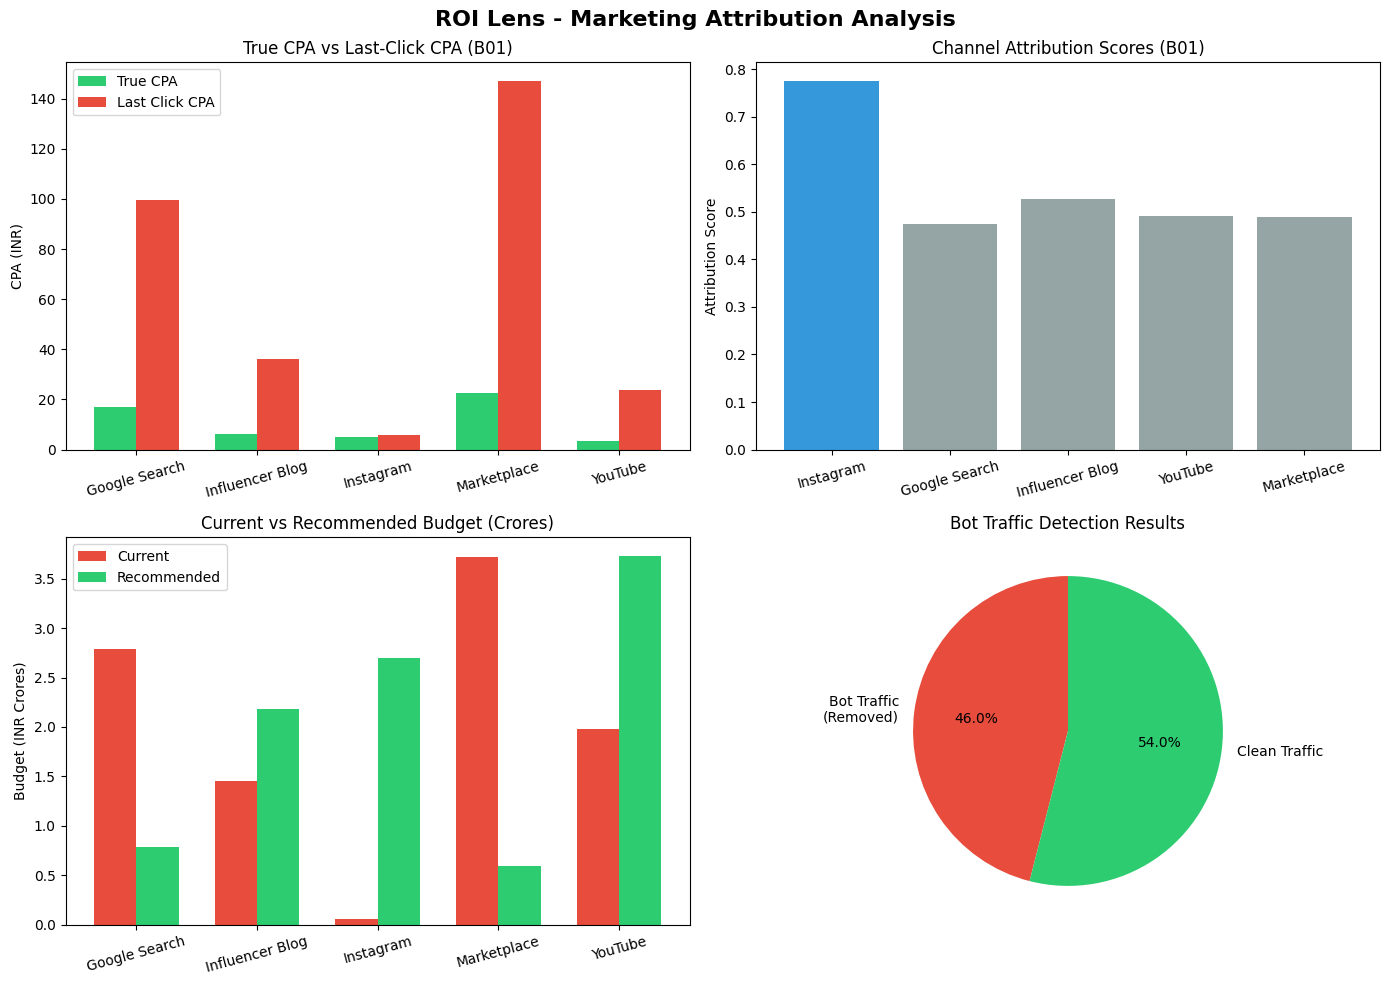

Chart saved!


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('ROI Lens - Marketing Attribution Analysis', fontsize=16, fontweight='bold')

# Plot 1 - True CPA vs Last Click CPA
ax1 = axes[0,0]
x = range(len(cpa_df))
width = 0.35
ax1.bar([i-width/2 for i in x], cpa_df['True_CPA'], width, label='True CPA', color='#2ecc71')
ax1.bar([i+width/2 for i in x], cpa_df['LastClick_CPA'], width, label='Last Click CPA', color='#e74c3c')
ax1.set_xticks(x)
ax1.set_xticklabels(cpa_df.index, rotation=15)
ax1.set_title('True CPA vs Last-Click CPA (B01)')
ax1.set_ylabel('CPA (INR)')
ax1.legend()

# Plot 2 - Attribution Scores
ax2 = axes[0,1]
colors = ['#3498db' if v == max(attribution_df.loc['B01'].values) else '#95a5a6'
          for v in attribution_df.loc['B01'].values]
ax2.bar(attribution_df.columns, attribution_df.loc['B01'].values, color=colors)
ax2.set_title('Channel Attribution Scores (B01)')
ax2.set_ylabel('Attribution Score')
ax2.set_xticklabels(attribution_df.columns, rotation=15)

# Plot 3 - Current vs Recommended Budget
ax3 = axes[1,0]
current = cs[cs['Brand_ID']=='B01'].groupby('Channel')['Total_Budget_Allocated'].sum()
recommended = realloc_df[realloc_df['Brand']=='B01'].set_index('Channel')['Recommended_Budget_INR']
x = range(len(current))
ax3.bar([i-width/2 for i in x], current.values/1e7, width, label='Current', color='#e74c3c')
ax3.bar([i+width/2 for i in x], recommended.values/1e7, width, label='Recommended', color='#2ecc71')
ax3.set_xticks(x)
ax3.set_xticklabels(current.index, rotation=15)
ax3.set_title('Current vs Recommended Budget (Crores)')
ax3.set_ylabel('Budget (INR Crores)')
ax3.legend()

# Plot 4 - Bot vs Clean Traffic
ax4 = axes[1,1]
labels = ['Bot Traffic\n(Removed)', 'Clean Traffic']
sizes = [21992, 25804]
colors = ['#e74c3c', '#2ecc71']
ax4.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
ax4.set_title('Bot Traffic Detection Results')

plt.tight_layout()
plt.savefig('roi_lens_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved!")

In [ ]:
print("=" * 60)
print("ROI LENS - EXECUTIVE SUMMARY")
print("=" * 60)

print(f"""
KEY FINDINGS:

1. BOT TRAFFIC
   - {len(bot_users)} bot users detected ({len(bot_users)/tp['User_ID'].nunique()*100:.0f}% of all users)
   - 21,992 fraudulent interactions removed
   - Estimated wasted spend on bots: significant

2. ATTRIBUTION TRUTH (vs Last-Click Lies)
   - YouTube TRUE CPA: INR 3.60  (Last-Click said INR 23.65)
   - Influencer TRUE CPA: INR 6.15 (Last-Click said INR 36.35)
   - Marketplace TRUE CPA: INR 22.49 (most expensive)
   - Google Search TRUE CPA: INR 17.01

3. CHANNEL ROLES
   - Instagram: Primary CONVERTER (68% of purchases last-touch)
   - YouTube: Best VALUE channel (lowest true CPA)
   - Influencer Blog: Strong MID-FUNNEL primer
   - Marketplace: Most EXPENSIVE - needs frequency cap
   - Google Search: OVERRATED by last-click model

4. RECOMMENDED REALLOCATION (per INR 10 Crore per brand)
   - YouTube:         37.3% (INR 3.73 Cr) UP from current
   - Instagram:       27.0% (INR 2.70 Cr)
   - Influencer Blog: 21.8% (INR 2.18 Cr) UP from current
   - Google Search:    7.9% (INR 0.79 Cr) DOWN
   - Marketplace:      6.0% (INR 0.60 Cr) DOWN - add frequency cap

5. CAMPAIGNS TO DEFUND
   - Reduce Marketplace budget by 40%+
   - Reduce Google Search by 50%+
   - Reinvest into YouTube and Influencer Blog
""")
print("=" * 60)

ROI LENS - EXECUTIVE SUMMARY

KEY FINDINGS:

1. BOT TRAFFIC
   - 970 bot users detected (12% of all users)
   - 21,992 fraudulent interactions removed
   - Estimated wasted spend on bots: significant

2. ATTRIBUTION TRUTH (vs Last-Click Lies)
   - YouTube TRUE CPA: INR 3.60  (Last-Click said INR 23.65) 
   - Influencer TRUE CPA: INR 6.15 (Last-Click said INR 36.35)
   - Marketplace TRUE CPA: INR 22.49 (most expensive)
   - Google Search TRUE CPA: INR 17.01

3. CHANNEL ROLES
   - Instagram: Primary CONVERTER (68% of purchases last-touch)
   - YouTube: Best VALUE channel (lowest true CPA)
   - Influencer Blog: Strong MID-FUNNEL primer
   - Marketplace: Most EXPENSIVE - needs frequency cap
   - Google Search: OVERRATED by last-click model

4. RECOMMENDED REALLOCATION (per INR 10 Crore per brand)
   - YouTube:         37.3% (INR 3.73 Cr) UP from current
   - Instagram:       27.0% (INR 2.70 Cr)
   - Influencer Blog: 21.8% (INR 2.18 Cr) UP from current
   - Google Search:    7.9% (INR 0.79 

In [ ]:
# Save all outputs
cpa_df.to_csv('b01_cpa_analysis.csv')
all_brands_df.to_csv('all_brands_attribution.csv')
realloc_df.to_csv('budget_reallocation.csv')

print("Files saved:")
print("  roi_lens_analysis.png")
print("  b01_cpa_analysis.csv")
print("  all_brands_attribution.csv")
print("  budget_reallocation.csv")
print("\nNotebook is complete! Download these files for your submission.")

Files saved:
  roi_lens_analysis.png
  b01_cpa_analysis.csv
  all_brands_attribution.csv
  budget_reallocation.csv

Notebook is complete! Download these files for your submission.
